<a href="https://colab.research.google.com/github/soorbaev/ai-labs/blob/main/campus_life_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis (EDA)

# Разведочный анализ данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('bytebrew-campus-cafe-orders.csv')

df.head()

,order_id,day_of_week,time_slot,student_year,faculty,drink,size,food_item,is_member,payment,raining,price,prep_minutes,calories,tip,rating,study_hours_today,prior_coffee_cups
0,B0301,Tue,late_night,2,Bio,tea,L,croissant,no,card,no,4.49,8,288,0.10,3.0,1.9,1
1,B0266,Tue,morning,2,Bio,cappuccino,L,sandwich,no,campus_card,no,8.16,6,558,0.67,4.0,1.3,3
2,B0064,Fri,late_night,1,Business,hot_chocolate,S,cookie,no,campus_card,yes,4.08,8,382,0.84,4.0,4.8,0
3,B0197,Thu,afternoon,4,Business,americano,S,cookie,yes,card,no,3.19,6,194,0.89,4.0,3.2,0
4,B0261,Fri,morning,2,Design,americano,M,none,yes,card,no,2.48,5,11,0.79,3.0,4.7,1


In [5]:
df.shape

(365, 18)

### Что означают столбцы?

| Столбец | Смысл |
|---------|--------|
| `order_id` | идентификатор заказа |
| `day_of_week` | день недели |
| `time_slot` | время суток: morning / afternoon / evening / late_night |
| `student_year` | курс обучения (1–4) |
| `faculty` | факультет |
| `drink` | напиток |
| `size` | размер S / M / L |
| `food_item` | еда (`none`, если только напиток) |
| `is_member` | есть ли карта лояльности |
| `payment` | способ оплаты |
| `raining` | шёл ли дождь в тот день |
| `price` | цена заказа |
| `prep_minutes` | время приготовления (мин) |
| `calories` | оценка калорий |
| `tip` | чаевые |
| `rating` | оценка сервиса 1–5 |
| `study_hours_today` | сколько часов студент уже учился сегодня |
| `prior_coffee_cups` | сколько кофе уже было до этого заказа

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   order_id           365 non-null    object 
 1   day_of_week        365 non-null    object 
 2   time_slot          365 non-null    object 
 3   student_year       365 non-null    int64  
 4   faculty            365 non-null    object 
 5   drink              365 non-null    object 
 6   size               365 non-null    object 
 7   food_item          365 non-null    object 
 8   is_member          365 non-null    object 
 9   payment            365 non-null    object 
 10  raining            365 non-null    object 
 11  price              365 non-null    float64
 12  prep_minutes       365 non-null    int64  
 13  calories           365 non-null    int64  
 14  tip                336 non-null    float64
 15  rating             356 non-null    float64
 16  study_hours_today  365 non

In [7]:
df.describe()

,student_year,price,prep_minutes,calories,tip,rating,study_hours_today,prior_coffee_cups
count,365.000000,365.000000,365.000000,365.000000,336.000000,356.000000,365.000000,365.000000
mean,2.224658,4.903836,5.980822,294.487671,0.570208,3.904494,3.705479,1.320548
std,1.086351,1.986780,2.434226,193.690356,0.339604,0.751998,1.451135,1.108776
min,1.000000,1.610000,1.000000,0.000000,0.000000,2.000000,0.300000,0.000000
25%,1.000000,3.220000,4.000000,141.000000,0.310000,3.000000,2.700000,0.000000
50%,2.000000,4.480000,6.000000,288.000000,0.580000,4.000000,3.600000,1.000000
75%,3.000000,6.570000,8.000000,436.000000,0.802500,4.000000,4.600000,2.000000
max,4.000000,9.340000,12.000000,747.000000,1.560000,5.000000,8.000000,4.000000


In [8]:
df.columns.tolist()

['order_id',
 'day_of_week',
 'time_slot',
 'student_year',
 'faculty',
 'drink',
 'size',
 'food_item',
 'is_member',
 'payment',
 'raining',
 'price',
 'prep_minutes',
 'calories',
 'tip',
 'rating',
 'study_hours_today',
 'prior_coffee_cups']

In [9]:
df['day_of_week'].value_counts()

,count
day_of_week,
Fri,72
Tue,60
Thu,56
Wed,54
Mon,43
Sat,42
Sun,38


In [10]:
print(df['drink'].value_counts())

drink
cappuccino       60
cold_brew        57
latte            53
smoothie         53
tea              50
americano        47
hot_chocolate    45
Name: count, dtype: int64


In [11]:
df['food_item'].unique()

array(['croissant', 'sandwich', 'cookie', 'none', 'soup', 'salad'],
      dtype=object)

In [12]:
df['food_item'].value_counts()

,count
food_item,
none,145
sandwich,73
croissant,54
salad,39
cookie,38
soup,16


In [13]:
print(df['time_slot'].value_counts())

time_slot
evening       99
afternoon     95
morning       93
late_night    78
Name: count, dtype: int64


## Легкая очистка

In [14]:
print( "exact duplicate rows: ", df.duplicated().sum() )

exact duplicate rows:  5


In [ ]:
df[df.duplicated()]

,order_id,day_of_week,time_slot,student_year,faculty,drink,size,food_item,is_member,payment,raining,price,prep_minutes,calories,tip,rating,study_hours_today,prior_coffee_cups
83,B0172,Sat,late_night,2,CS,latte,M,soup,no,card,no,6.57,7,353,1.27,4.0,2.1,4
197,B0211,Thu,late_night,1,Arts,smoothie,L,none,yes,card,no,4.37,7,304,0.41,4.0,2.8,1
244,B0267,Fri,morning,4,Bio,americano,M,none,no,card,no,2.66,5,7,NaN,3.0,1.2,1
273,B0119,Sat,evening,1,Law,smoothie,M,sandwich,no,card,yes,8.52,5,691,0.42,4.0,1.2,1
361,B0331,Mon,morning,4,Law,cold_brew,S,croissant,no,card,no,5.14,8,301,0.69,NaN,2.7,2


## Очистка

In [15]:
df_clean = df.drop_duplicates().copy()
print("shape after drop_duplicates", df_clean.shape)

shape after drop_duplicates (360, 18)


In [16]:
tip_median = df_clean['tip'].median()
print("tip median: ", tip_median)

df_clean['tip'] = df_clean['tip'].fillna(tip_median)

tip median:  0.58


In [17]:
rating_median = df_clean['rating'].median()
print("rating median: ", rating_median)

df_clean['rating'] = df_clean['rating'].fillna(rating_median)

rating median:  4.0


In [19]:
df_clean = df_clean.drop(['rating'], axis = 1)

In [ ]:
print(df_clean.isna().sum())

order_id             0
day_of_week          0
time_slot            0
student_year         0
faculty              0
drink                0
size                 0
food_item            0
is_member            0
payment              0
raining              0
price                0
prep_minutes         0
calories             0
tip                  0
rating               0
study_hours_today    0
prior_coffee_cups    0
dtype: int64


## 5. Анализы: фильтры и groupby

Несколько коротких вопросов к данным — по одной идее на ячейку.

### 5.1. Средний чек у членов программы лояльности и остальных


In [21]:
df.groupby('is_member')['price'].mean()

,price
is_member,
no,5.120744
yes,4.477073


### 5.2. Какие напитки берут вечером и ночью?


In [23]:
df[df['time_slot'].isin(['evening', 'night', 'late_night'])]['drink'].value_counts()

,count
drink,
cold_brew,32
cappuccino,30
smoothie,28
americano,23
hot_chocolate,23
latte,22
tea,19


### 5.3. Среднее время приготовления по типу еды


In [24]:
df.groupby('food_item')['prep_minutes'].mean()

,prep_minutes
food_item,
cookie,6.947368
croissant,7.574074
none,4.124138
salad,7.512821
sandwich,6.876712
soup,7.312500


### 5.4. Дождь и горячий шоколад — совпадение?


In [25]:
# Смотрим, при какой погоде (raining) чаще берут горячий шоколад (или какао/chocolate)
df[df['drink'].str.contains('chocolate', case=False, na=False)]['raining'].value_counts()

,count
raining,
no,35
yes,10


### 5.5. Курс студента и средний рейтинг / чаевые


In [26]:
df.groupby('student_year')[['rating', 'tip']].mean()

,rating,tip
student_year,,
1,3.875000,0.526930
2,3.902174,0.621250
3,3.988506,0.606585
4,3.842105,0.521346


### 5.6. Факультет и калории (кто «слаще» заказывает?)


In [27]:
df.groupby('faculty')['calories'].mean().sort_values(ascending=False)

,calories
faculty,
Law,321.150000
Arts,305.459016
Business,301.941176
CS,290.359375
Design,281.463768
Bio,269.716667


## 6. Графики

Подписываем оси и заголовки. Без лишнего декора. Каждую диаграмму следет построить через plt и seaborn


### 6.1. Гистограмма цены

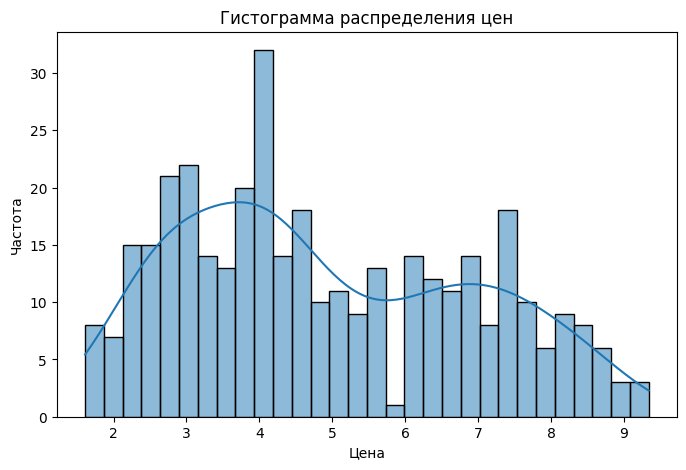

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df['price'], bins=30, kde=True)
plt.title('Гистограмма распределения цен')
plt.xlabel('Цена')
plt.ylabel('Частота')
plt.show()

### 6.2. Столбчатая диаграмма: заказы по дням недели


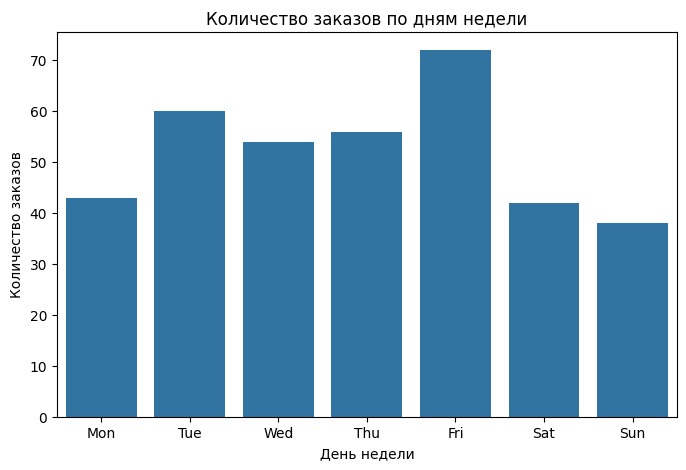

In [29]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='day_of_week', order=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
plt.title('Количество заказов по дням недели')
plt.xlabel('День недели')
plt.ylabel('Количество заказов')
plt.show()

### 6.3. Средняя цена по напитку (barh удобнее читать)


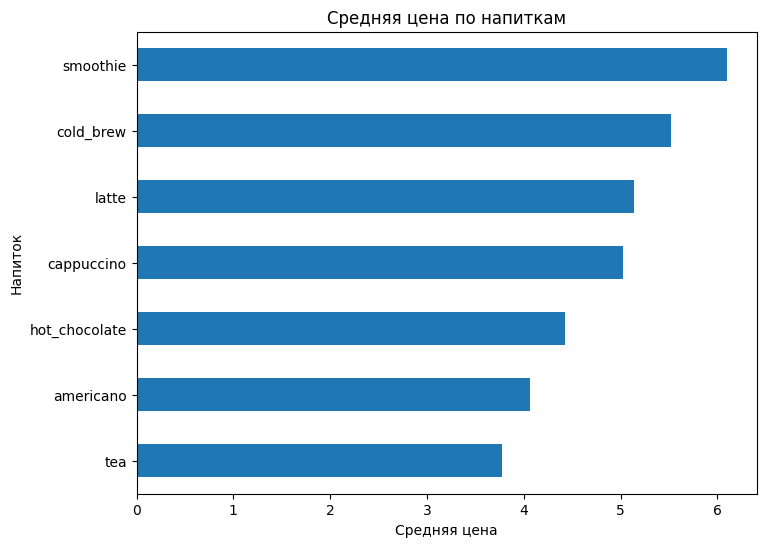

In [30]:
plt.figure(figsize=(8, 6))
avg_price = df.groupby('drink')['price'].mean().sort_values()
avg_price.plot(kind='barh')
plt.title('Средняя цена по напиткам')
plt.xlabel('Средняя цена')
plt.ylabel('Напиток')
plt.show()

### 6.4. Scatter: время приготовления vs рейтинг


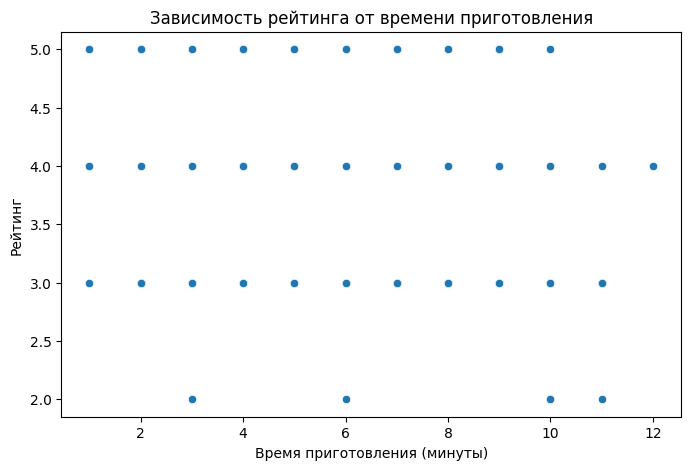

In [31]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='prep_minutes', y='rating')
plt.title('Зависимость рейтинга от времени приготовления')
plt.xlabel('Время приготовления (минуты)')
plt.ylabel('Рейтинг')
plt.show()

### 6.5. Boxplot калорий по размеру стакана


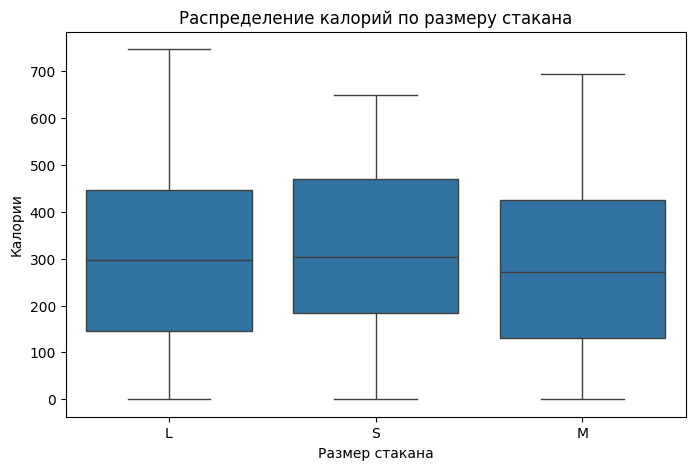

In [32]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='size', y='calories')
plt.title('Распределение калорий по размеру стакана')
plt.xlabel('Размер стакана')
plt.ylabel('Калории')
plt.show()

### 6.6. Связь учёбы и кофе: study hours vs prior cups (scatter + лёгкий цвет по member)

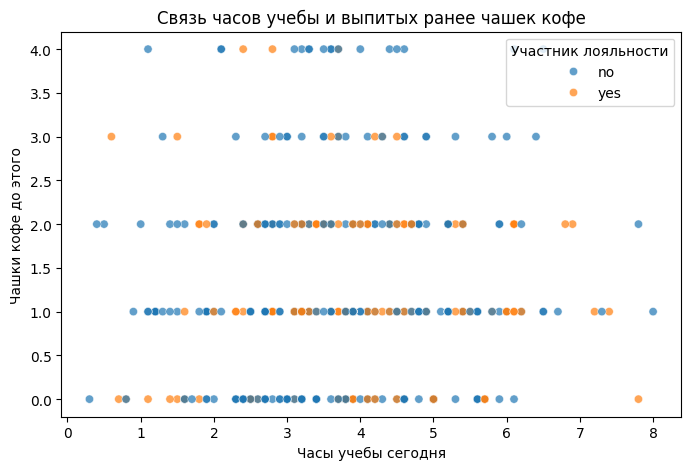

In [33]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='study_hours_today', y='prior_coffee_cups', hue='is_member', alpha=0.7)
plt.title('Связь часов учебы и выпитых ранее чашек кофе')
plt.xlabel('Часы учебы сегодня')
plt.ylabel('Чашки кофе до этого')
plt.legend(title='Участник лояльности')
plt.show()

### Задание A

Посчитайте **средний `tip`** для каждого способа оплаты (`payment`).  
Отсортируйте по убыванию среднего чаевого. Постройте bar chart.


payment
card           0.617669
campus_card    0.593525
cash           0.362745
Name: tip, dtype: float64


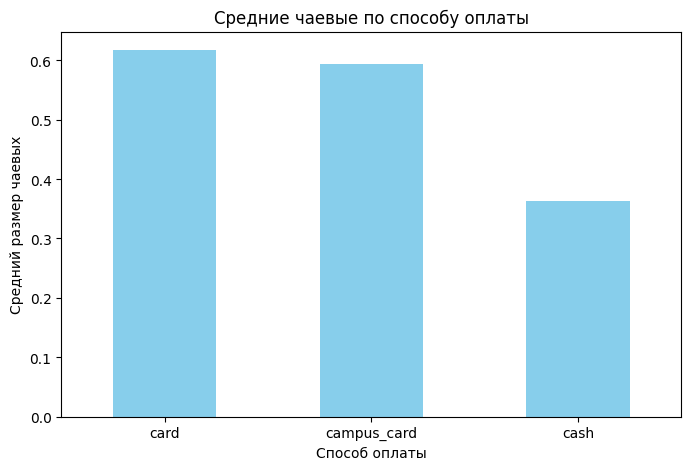

In [34]:
avg_tip = df.groupby('payment')['tip'].mean().sort_values(ascending=False)
print(avg_tip)

plt.figure(figsize=(8, 5))
avg_tip.plot(kind='bar', color='skyblue')
plt.title('Средние чаевые по способу оплаты')
plt.xlabel('Способ оплаты')
plt.ylabel('Средний размер чаевых')
plt.xticks(rotation=0)
plt.show()

### Задание B

Сделайте фильтр: только заказы с едой (`food_item != "none"`) **и** `time_slot == "morning"`.  
Сколько таких строк? Какой самый частый `drink` в этом срезе?


In [35]:
filtered_df = df[(df['food_item'] != 'none') & (df['time_slot'] == 'morning')]

# 1. Сколько строк
print(f"Количество строк: {len(filtered_df)}")

# 2. Самый частый напиток (drink)
top_drink = filtered_df['drink'].mode()[0]
print(f"Самый частый напиток утром с едой: {top_drink}")

Количество строк: 59
Самый частый напиток утром с едой: cappuccino
